# Retail Sales Analysis: Exploratory Data Analysis

**Objective.** Explore transaction-level retail sales data and describe how revenue and transaction values vary across product categories, customer demographics and time.

**Dataset.** 1,000 transactions from January 2023 to January 2024. The dataset is synthetic/fictional according to its Kaggle description; it should be treated as a practice dataset, not evidence about a real retailer. See the project `README.md` for the source and download instructions.

**Business questions**
1. Is the dataset complete and internally consistent?
2. What are the headline sales metrics and how are transaction amounts distributed?
3. How does revenue differ across product categories and customer groups?
4. How do sales vary by weekday and month?

**Approach.** Data validation, descriptive statistics, `groupby`/pivot-table analysis and visualizations with pandas and matplotlib. The analysis is descriptive; it does not establish causation.


## 0. Setup and loading

Run this notebook from its own folder in Jupyter. The dataset is expected at `../data/retail_sales_dataset.csv`.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

DATA_PATH = Path("../data/retail_sales_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Download it from the Kaggle source "
        "linked in the project README and place it in the data/ folder."
    )

# Format chart axes with thousands separators.
thousands = StrMethodFormatter("{x:,.0f}")

df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


Shape: (1000, 9)
Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


## 1. Data quality checks

Check column types, missing values, duplicate records, identifier uniqueness, date coverage and basic business rules. In this dataset, `Total Amount` should equal `Quantity * Price per Unit`.


In [2]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


`Date` is parsed as a datetime column so it can be used for time-based analysis.


In [4]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date dtype:", df["Date"].dtype)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Date dtype: datetime64[ns]
Date range: 2023-01-01 to 2024-01-01


In [5]:
print("Unique transaction IDs:", df["Transaction ID"].nunique())
print("Duplicate transaction IDs:", df["Transaction ID"].duplicated().sum())
print("Unique customer IDs:", df["Customer ID"].nunique())

print("Invalid ages:", ((df["Age"] < 18) | (df["Age"] > 100)).sum())
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["Price per Unit"] <= 0).sum())

amount_mismatches = (df["Total Amount"] != df["Quantity"] * df["Price per Unit"]).sum()
print("Amount mismatches:", amount_mismatches)

print("Genders:", sorted(df["Gender"].dropna().unique()))
print("Categories:", sorted(df["Product Category"].dropna().unique()))


Unique transaction IDs: 1000
Duplicate transaction IDs: 0
Unique customer IDs: 1000
Invalid ages: 0
Invalid quantities: 0
Invalid prices: 0
Amount mismatches: 0
Genders: ['Female', 'Male']
Categories: ['Beauty', 'Clothing', 'Electronics']


## 2. Key metrics

The headline numbers used throughout the rest of the notebook.

In [6]:
total_revenue = df["Total Amount"].sum()

print(f"Transactions:               {len(df):,}")
print(f"Total revenue:              {total_revenue:,}")
print(f"Average transaction amount: {df['Total Amount'].mean():,.2f}")
print(f"Median transaction amount:  {df['Total Amount'].median():,.2f}")

Transactions:               1,000
Total revenue:              456,000
Average transaction amount: 456.00
Median transaction amount:  135.00


## 3. Distribution of transaction amounts

The mean and the median of the transaction amount can differ a lot when a few large transactions pull the average up.
Percentiles and a histogram show how strongly the distribution is skewed.

90th percentile: 1200.0
95th percentile: 1500.0
Maximum: 2000


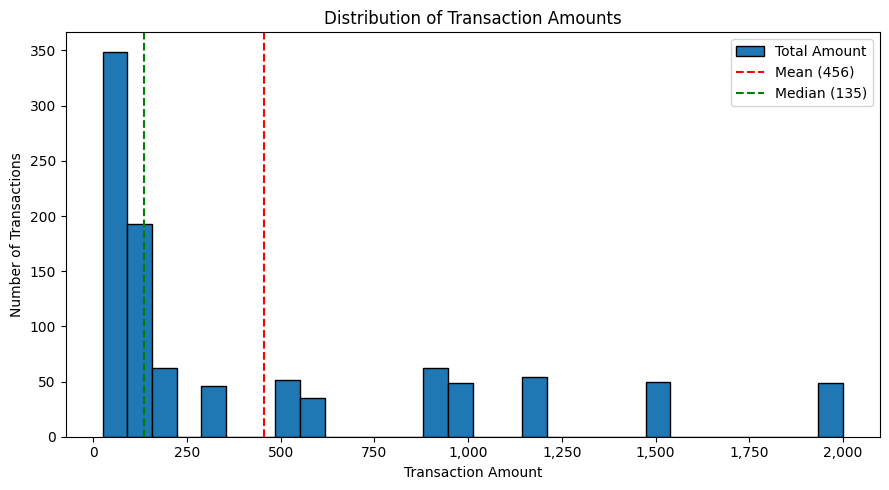

In [7]:
amount = df["Total Amount"]

print("90th percentile:", amount.quantile(0.90))
print("95th percentile:", amount.quantile(0.95))
print("Maximum:", amount.max())

ax = amount.plot(kind="hist", bins=30, figsize=(9, 5), edgecolor="black")
ax.axvline(amount.mean(), color="red", linestyle="--", label=f"Mean ({amount.mean():,.0f})")
ax.axvline(amount.median(), color="green", linestyle="--", label=f"Median ({amount.median():,.0f})")

ax.set_title("Distribution of Transaction Amounts")
ax.set_xlabel("Transaction Amount")
ax.set_ylabel("Number of Transactions")
ax.xaxis.set_major_formatter(thousands)
ax.legend()

plt.tight_layout()
plt.show()

## 4. Product categories

One table with transactions, revenue, average and median amount per category, followed by the revenue share.

,Transactions,Total_Revenue,Average_Sale,Median_Sale,Revenue_Share_%
Product Category,,,,,
Electronics,342,156905,458.79,150.0,34.41
Clothing,351,155580,443.25,120.0,34.12
Beauty,307,143515,467.48,120.0,31.47


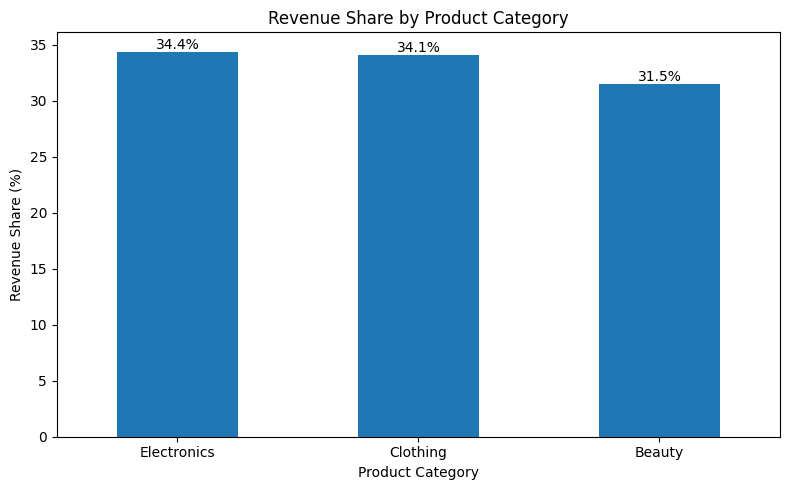

In [8]:
category_analysis = (
    df.groupby("Product Category")
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Amount", "sum"),
        Average_Sale=("Total Amount", "mean"),
        Median_Sale=("Total Amount", "median")
    )
    .sort_values("Total_Revenue", ascending=False)
)
category_analysis["Revenue_Share_%"] = category_analysis["Total_Revenue"] / total_revenue * 100

display(category_analysis.round(2))

ax = category_analysis["Revenue_Share_%"].plot(kind="bar", figsize=(8, 5))

ax.set_title("Revenue Share by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Revenue Share (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Gender

Overall comparison first, then revenue by product category and gender.

In [9]:
gender_analysis = (
    df.groupby("Gender")
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Amount", "sum"),
        Average_Sale=("Total Amount", "mean")
    )
)

display(gender_analysis.round(2))

,Transactions,Total_Revenue,Average_Sale
Gender,,,
Female,510,232840,456.55
Male,490,223160,455.43


Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


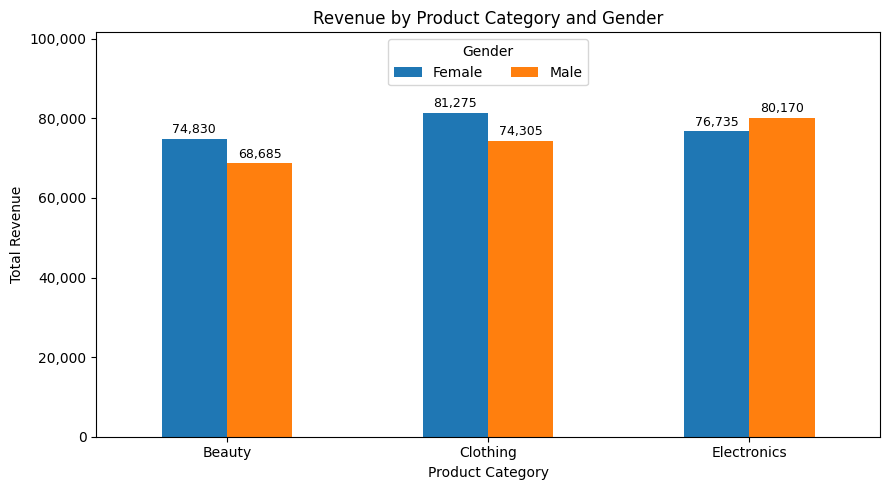

In [10]:
gender_category = df.pivot_table(
    index="Product Category",
    columns="Gender",
    values="Total Amount",
    aggfunc="sum",
    fill_value=0
)

display(gender_category)

ax = gender_category.plot(kind="bar", figsize=(9, 5))

for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:,.0f}" for v in container.datavalues], padding=2, fontsize=9)

ax.set_title("Revenue by Product Category and Gender")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Revenue")
ax.set_ylim(0, gender_category.values.max() * 1.25)   # headroom so the legend does not cover the bars
ax.yaxis.set_major_formatter(thousands)
ax.legend(title="Gender", loc="upper center", ncol=2)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Age groups

Compare the average transaction amount across age bands. The first band (18–24) covers seven ages, while the other bands cover ten; therefore, transaction counts and total revenue across bands should not be compared without accounting for the different group widths.


Rows without an age group: 0


,Transactions,Total_Revenue,Average_Transaction_Amount,Median_Transaction_Amount
Age Group,,,,
18–24,149,74650,501.01,100.0
25–34,203,97090,478.28,200.0
35–44,207,96835,467.80,120.0
45–54,225,97235,432.16,150.0
55–64,216,90190,417.55,120.0


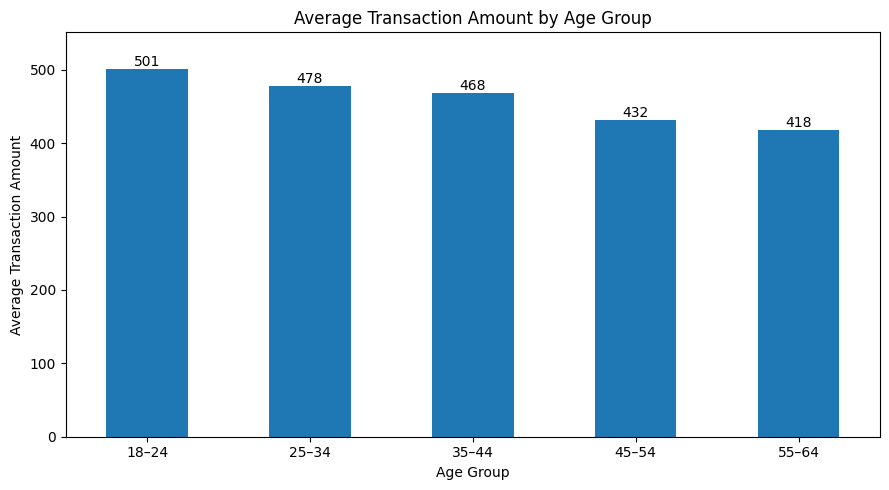

In [11]:
bins = [18, 25, 35, 45, 55, 65]
labels = ["18–24", "25–34", "35–44", "45–54", "55–64"]

df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)
print("Rows without an age group:", df["Age Group"].isna().sum())

age_analysis = (
    df.groupby("Age Group", observed=False)
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Amount", "sum"),
        Average_Transaction_Amount=("Total Amount", "mean"),
        Median_Transaction_Amount=("Total Amount", "median")
    )
)

display(age_analysis.round(2))

ax = age_analysis["Average_Transaction_Amount"].plot(kind="bar", figsize=(9, 5))
ax.bar_label(
    ax.containers[0],
    labels=[f"{value:,.0f}" for value in age_analysis["Average_Transaction_Amount"]]
)
ax.set_title("Average Transaction Amount by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Average Transaction Amount")
ax.margins(y=0.1)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Day of week

Transactions, revenue and average amount for each weekday.

,Transactions,Total_Revenue,Average_Sale
Day of Week,,,
Monday,146,70250,481.16
Tuesday,161,69440,431.30
Wednesday,139,58770,422.81
Thursday,123,53835,437.68
Friday,143,66290,463.57
Saturday,150,78815,525.43
Sunday,138,58600,424.64


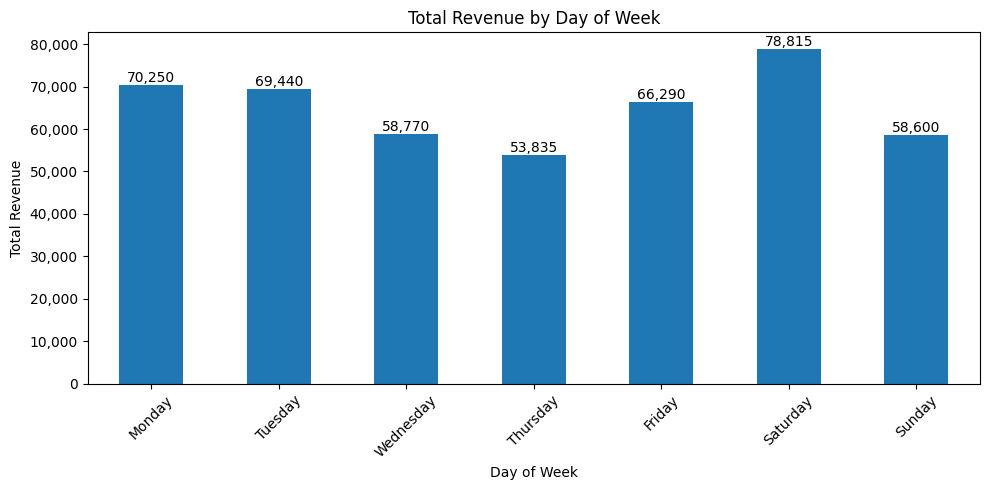

In [12]:
df["Day of Week"] = df["Date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("Day of Week")
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Amount", "sum"),
        Average_Sale=("Total Amount", "mean")
    )
    .reindex(weekday_order)
)

display(weekday_sales.round(2))

ax = weekday_sales["Total_Revenue"].plot(kind="bar", figsize=(10, 5))
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}" for v in weekday_sales["Total_Revenue"]])

ax.set_title("Total Revenue by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Total Revenue")
ax.yaxis.set_major_formatter(thousands)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Monthly sales

January 2024 contains only two transactions and ends on January 1 in this dataset, so it is an incomplete month. It is excluded from month-to-month comparisons to avoid treating partial coverage as a genuine sales decline.


In [13]:
monthly_analysis = (
    df.groupby(df["Date"].dt.to_period("M"))
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Revenue=("Total Amount", "sum"),
        Average_Sale=("Total Amount", "mean")
    )
)

# Exclude the last month if the data stops before the end of that month
last_date = df["Date"].max()
last_month = last_date.to_period("M")
if last_date < last_date + pd.offsets.MonthEnd(0):
    n_partial = monthly_analysis.loc[last_month, "Transactions"]
    print(f"Excluded partial month: {last_month} ({n_partial} transactions, last date {last_date.date()})")
    monthly_analysis = monthly_analysis.drop(index=last_month)

display(monthly_analysis.round(2))

best_month = monthly_analysis["Total_Revenue"].idxmax()
worst_month = monthly_analysis["Total_Revenue"].idxmin()
print("Best month: ", best_month, "| revenue:", f"{monthly_analysis.loc[best_month, 'Total_Revenue']:,}")
print("Worst month:", worst_month, "| revenue:", f"{monthly_analysis.loc[worst_month, 'Total_Revenue']:,}")

Excluded partial month: 2024-01 (2 transactions, last date 2024-01-01)


,Transactions,Total_Revenue,Average_Sale
Date,,,
2023-01,76,35450,466.45
2023-02,85,44060,518.35
2023-03,73,28990,397.12
2023-04,86,33870,393.84
2023-05,105,53150,506.19
2023-06,77,36715,476.82
2023-07,72,35465,492.57
2023-08,94,36960,393.19
2023-09,65,23620,363.38


Best month:  2023-05 | revenue: 53,150
Worst month: 2023-09 | revenue: 23,620


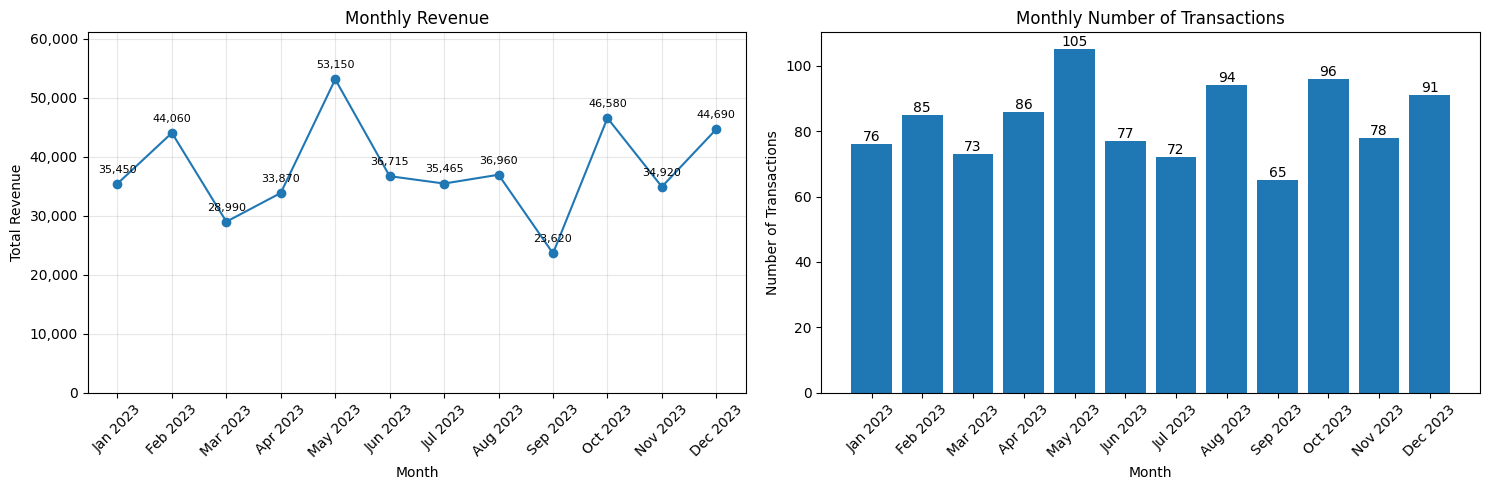

In [14]:
month_labels = list(monthly_analysis.index.strftime("%b %Y"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(month_labels, monthly_analysis["Total_Revenue"], marker="o")
for x, v in zip(month_labels, monthly_analysis["Total_Revenue"]):
    axes[0].annotate(f"{v:,.0f}", (x, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total Revenue")
axes[0].yaxis.set_major_formatter(thousands)
axes[0].set_ylim(0, monthly_analysis["Total_Revenue"].max() * 1.15)   # start at zero: no exaggerated swings
axes[0].grid(True, alpha=0.3)

bars = axes[1].bar(month_labels, monthly_analysis["Transactions"])
axes[1].bar_label(bars)
axes[1].set_title("Monthly Number of Transactions")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Transactions")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Key Findings

1. **Overall:** 1,000 transactions from January 2023 to January 1, 2024 generated 456,000 in total sales. The average transaction amount is 456.00, while the median is 135.00. The currency is not specified in the source data.
2. **Transaction amounts:** the 90th percentile is 1,200 and the maximum is 2,000. The mean being much higher than the median indicates a strongly right-skewed distribution: a relatively small number of high-value transactions pull up the average.
3. **Product categories:** revenue is distributed relatively evenly: Electronics 156,905 (34.4%), Clothing 155,580 (34.1%) and Beauty 143,515 (31.5%). Electronics leads Clothing by only 1,325, so the difference is small. Clothing has the most transactions (351); Beauty has the highest average transaction amount (467.48).
4. **Gender:** female customers account for 232,840 across 510 transactions and male customers for 223,160 across 490 transactions. Average transaction amounts are nearly identical (456.55 vs 455.43). These descriptive differences do not establish meaningful behavioural differences.
5. **Age:** the average transaction amount decreases across the observed age bands, from 501.01 (18–24) to 417.55 (55–64). This is a pattern in this synthetic sample, not evidence that age causes lower spending. The first age band is narrower than the others.
6. **Day of week:** Saturday has the highest revenue (78,815) and highest average transaction amount (525.43). Thursday has the lowest revenue (53,835). Tuesday has the most transactions (161), but a lower average transaction amount (431.30).
7. **Months:** among complete months in 2023, May has the highest revenue (53,150; 105 transactions) and September the lowest (23,620; 65 transactions). With only one year of observations, these results should not be described as seasonality.

## Limitations

- **Synthetic data:** the source describes the dataset as fictional. The results demonstrate an EDA workflow and do not describe a real business.
- **Small sample and short period:** 1,000 transactions over roughly one year are not enough to establish stable trends or seasonality.
- **One transaction per customer:** each customer ID appears once, so repeat purchases, retention and customer lifetime value cannot be analyzed.
- **Incomplete final month:** January 2024 contains only two transactions and is excluded from monthly comparisons.
- **Descriptive analysis only:** no hypothesis tests or confidence intervals were calculated. Small group differences should not be over-interpreted, and no causal conclusions can be drawn.
- **Unequal age bands:** the 18–24 group covers seven ages, while the other groups cover ten.
- **Missing business context:** currency, store, product-level detail, discounts and sales channels are not provided.
